# Titanic Survival Prediction Using Logistic Regression
**Course:** Fundamentals of Data Science  
**Case study:** Logistic Regression  
**Dataset:** Titanic passenger dataset (`titanic.csv`)

## Objective
Explore the Titanic dataset, prepare the data, train a Logistic Regression classifier to predict survival, evaluate it using classification metrics and an ROC curve, and interpret the model.

> **Important:** Review the output and explanations, and make sure you can explain each step in your own words before submission. Replace the title-page placeholders in your report with your own details.

## 1. Import libraries and load the dataset
We use pandas for data handling, Matplotlib/Seaborn for plots, and scikit-learn for preprocessing, modelling, and evaluation.

In [27]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")

DATA_PATH = "titanic.csv"  # Keep titanic.csv in the same folder as this notebook.
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Explore the dataset
The dataset contains passenger information and a binary target, `Survived` (0 = did not survive, 1 = survived). We inspect data types, summary statistics, and missing values before deciding how to preprocess.

In [28]:
print("Column data types:")
display(df.dtypes.to_frame("data_type"))

print("\nSummary statistics for numeric columns:")
display(df.describe().T)

print("\nMissing values by column:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

print("\nTarget distribution:")
display(df["Survived"].value_counts().rename(index={0: "Did not survive", 1: "Survived"}).to_frame("passengers"))

Column data types:


,data_type
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64



Summary statistics for numeric columns:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292



Missing values by column:


,missing_count
Cabin,687
Age,177
Embarked,2



Target distribution:


,passengers
Survived,
Did not survive,549
Survived,342


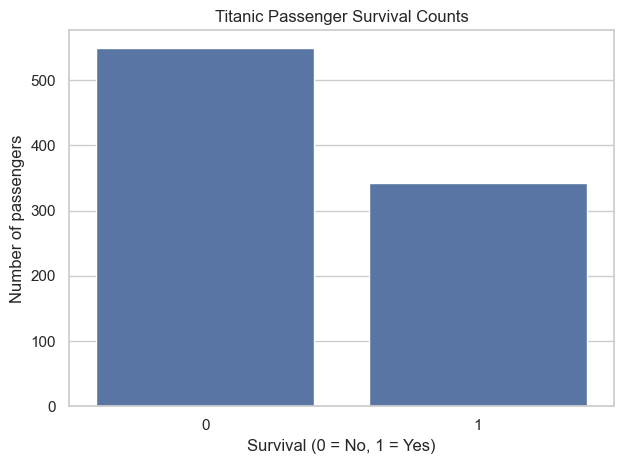

Overall survival rate: 38.4%


In [29]:
# Visualize the target distribution
ax = sns.countplot(data=df, x="Survived")
ax.set_title("Titanic Passenger Survival Counts")
ax.set_xlabel("Survival (0 = No, 1 = Yes)")
ax.set_ylabel("Number of passengers")
plt.tight_layout()
plt.show()

survival_rate = df["Survived"].mean()
print(f"Overall survival rate: {survival_rate:.1%}")

**Interpretation:** The bar chart shows the number of passengers in each target class. The survival rate is the proportion of records where `Survived` equals 1. A difference in class sizes matters because accuracy alone can hide weak performance on the smaller class.

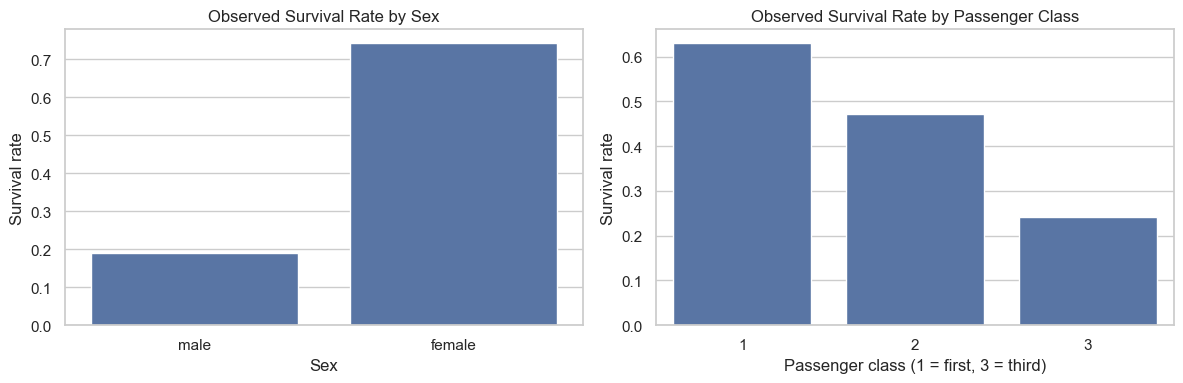

Survival rate by sex:


,survival_rate
Sex,
female,0.742038
male,0.188908


Survival rate by passenger class:


,survival_rate
Pclass,
1,0.629630
2,0.472826
3,0.242363


In [30]:
# Survival rate by sex and passenger class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="Sex", y="Survived", errorbar=None, ax=axes[0])
axes[0].set_title("Observed Survival Rate by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Survival rate")

sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None, ax=axes[1])
axes[1].set_title("Observed Survival Rate by Passenger Class")
axes[1].set_xlabel("Passenger class (1 = first, 3 = third)")
axes[1].set_ylabel("Survival rate")

plt.tight_layout()
plt.show()

print("Survival rate by sex:")
display(df.groupby("Sex")["Survived"].mean().rename("survival_rate").to_frame())
print("Survival rate by passenger class:")
display(df.groupby("Pclass")["Survived"].mean().rename("survival_rate").to_frame())

**Interpretation:** Compare the bars and tables rather than assuming causation. These are descriptive associations in the dataset. The model will estimate relationships while considering the other selected features.

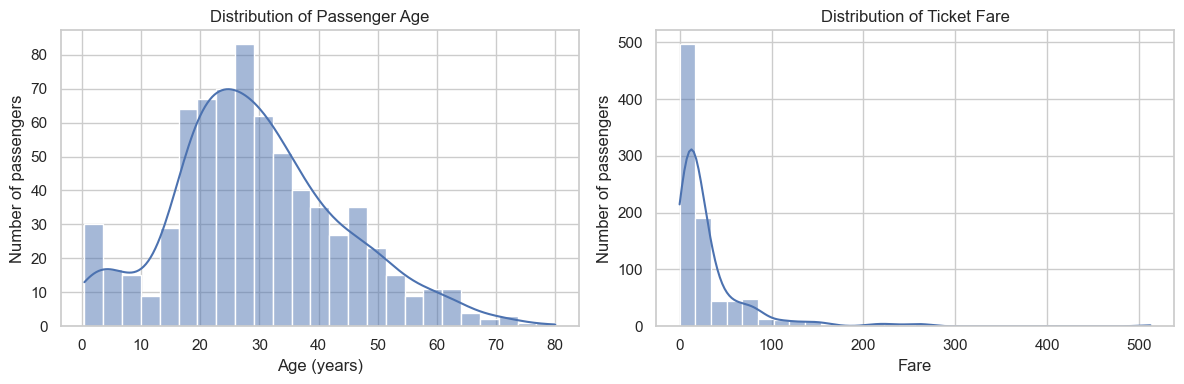

In [31]:
# Distribution of age and fare
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Age", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Passenger Age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of passengers")

sns.histplot(data=df, x="Fare", bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Ticket Fare")
axes[1].set_xlabel("Fare")
axes[1].set_ylabel("Number of passengers")
plt.tight_layout()
plt.show()

**Interpretation:** The age and fare plots help identify skewed distributions and missing observations. Fare is typically right-skewed, so a small number of passengers may have paid substantially higher fares than most passengers.

## 3. Data preprocessing and feature selection
We use `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked` as predictors. We exclude identifiers and high-cardinality text fields such as passenger name and ticket number. `Cabin` has many missing entries, so it is omitted in this baseline model.

Missing numeric values are filled using the training-set median; missing categorical values are filled using the most frequent training-set category. Categorical values are one-hot encoded, and numeric values are standardized. These operations are placed inside a scikit-learn pipeline to prevent information from the test set leaking into training.

In [32]:
target = "Survived"
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = df[features].copy()
y = df[target].copy()

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Features used:", features)

Training rows: 712
Testing rows: 179
Features used: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


## 4. Build and train the Logistic Regression model
Logistic Regression estimates the probability of the positive class (survival). The model classifies a passenger as a survivor when the estimated probability reaches the default threshold of 0.5.

In [33]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## 5. Evaluate model performance
We calculate accuracy, precision, recall, F1-score, and ROC-AUC on the held-out test set. Accuracy is the fraction of correct predictions; precision measures how many predicted survivors actually survived; recall measures how many actual survivors were identified; F1 is the harmonic mean of precision and recall; ROC-AUC measures ranking discrimination across classification thresholds.

In [34]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics_df = pd.DataFrame.from_dict(metrics, orient="index", columns=["Score"])
display(metrics_df.round(4))

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"], zero_division=0))

,Score
Accuracy,0.8045
Precision,0.7931
Recall,0.6667
F1-score,0.7244
ROC-AUC,0.8437


Classification report:
                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



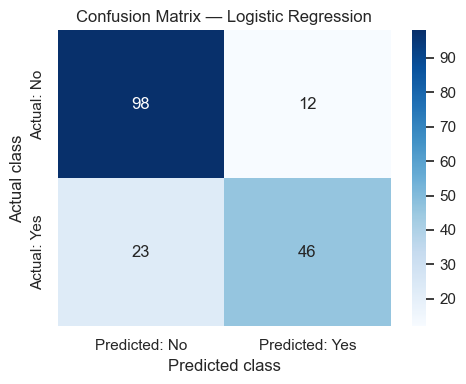

Confusion matrix layout: rows = actual class; columns = predicted class.
Correct non-survivor predictions: 98
Non-survivors predicted as survivors: 12
Survivors predicted as non-survivors: 23
Correct survivor predictions: 46


In [35]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"]
)
plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

print("Confusion matrix layout: rows = actual class; columns = predicted class.")
print(f"Correct non-survivor predictions: {cm[0,0]}")
print(f"Non-survivors predicted as survivors: {cm[0,1]}")
print(f"Survivors predicted as non-survivors: {cm[1,0]}")
print(f"Correct survivor predictions: {cm[1,1]}")

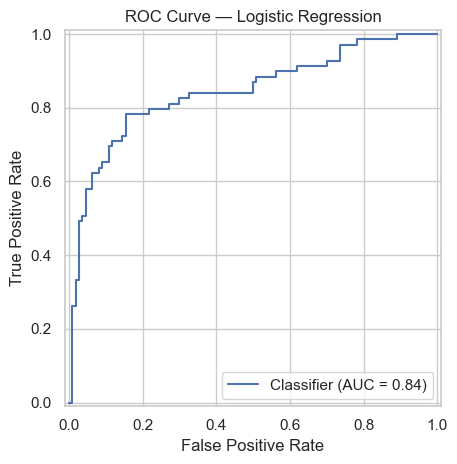

Test ROC-AUC: 0.8437


In [36]:
# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve — Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.tight_layout()
plt.show()

print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

**How to interpret evaluation:** Use the printed test metrics and confusion matrix to describe the model's strengths and limitations. Do not claim the model is excellent based on one score alone. Recall is particularly relevant if the goal is to identify as many actual survivors as possible; precision matters when avoiding false survivor predictions. ROC-AUC assesses discrimination across thresholds and does not itself select the best threshold.

## 6. Interpret Logistic Regression coefficients
For a Logistic Regression model, coefficients are changes in log-odds, holding other encoded features constant. A positive coefficient increases estimated log-odds of survival; a negative coefficient decreases them. Exponentiating a coefficient gives an odds ratio. These are associations within this model, not causal effects.

,feature,coefficient,odds_ratio,direction
6,categorical__Sex_male,-1.3207,0.2669,Lower modelled odds
0,numeric__Pclass,-0.9220,0.3977,Lower modelled odds
1,numeric__Age,-0.5028,0.6048,Lower modelled odds
9,categorical__Embarked_S,-0.3583,0.6989,Lower modelled odds
2,numeric__SibSp,-0.2606,0.7706,Lower modelled odds
3,numeric__Parch,-0.0664,0.9357,Lower modelled odds
7,categorical__Embarked_C,0.0322,1.0328,Higher modelled odds
4,numeric__Fare,0.1003,1.1055,Higher modelled odds
8,categorical__Embarked_Q,0.3048,1.3563,Higher modelled odds
5,categorical__Sex_female,1.2994,3.6673,Higher modelled odds


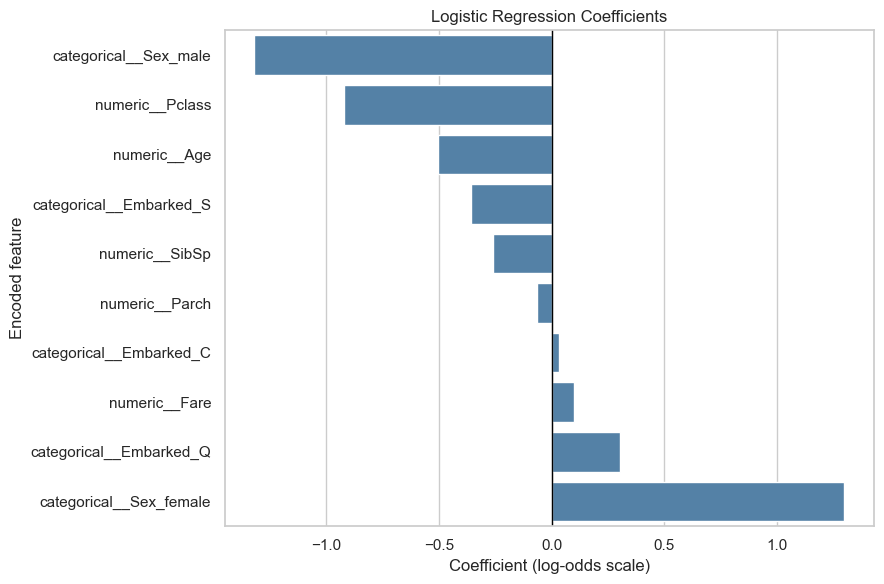

In [37]:
# Extract transformed feature names and fitted coefficients
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
except Exception:
    transformed_names = [f"feature_{i}" for i in range(len(fitted_classifier.coef_[0]))]

coef_df = pd.DataFrame({
    "feature": transformed_names,
    "coefficient": fitted_classifier.coef_[0]
})
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])
coef_df["direction"] = np.where(coef_df["coefficient"] >= 0, "Higher modelled odds", "Lower modelled odds")
coef_df = coef_df.sort_values("coefficient")

display(coef_df.round(4))

plt.figure(figsize=(9, 6))
plot_df = coef_df.sort_values("coefficient")
sns.barplot(data=plot_df, x="coefficient", y="feature", color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient (log-odds scale)")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()

**Interpretation guide:** A coefficient above zero is associated with higher modelled odds of survival; a coefficient below zero is associated with lower modelled odds, relative to the model's encoded reference category or per standardized numeric unit. Because numeric features are standardized and categorical features are one-hot encoded, coefficient magnitudes should be interpreted with their scales and encoding in mind. Do not treat coefficient magnitude alone as a formal significance test; this model does not report p-values.

## 7. Example prediction
The example below demonstrates how to use the fitted pipeline with one hypothetical passenger profile. It is an illustration, not a claim about a real passenger.

In [38]:
sample_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "female",
    "Age": 22,
    "SibSp": 1,
    "Parch": 0,
    "Fare": 15.0,
    "Embarked": "S"
}])

sample_probability = model.predict_proba(sample_passenger)[0, 1]
sample_class = model.predict(sample_passenger)[0]

print(f"Estimated survival probability: {sample_probability:.1%}")
print("Predicted class:", "Survived" if sample_class == 1 else "Did not survive")

Estimated survival probability: 57.6%
Predicted class: Survived


## 8. Conclusion
This case study demonstrates an end-to-end binary classification workflow using Logistic Regression on Titanic passenger data. Exploratory analysis identifies missing data and descriptive survival patterns. A preprocessing pipeline handles missing values, scales numeric variables, and encodes categorical variables. Performance is measured on a stratified held-out test set using accuracy, precision, recall, F1-score, ROC-AUC, a confusion matrix, and an ROC curve. Coefficients provide an interpretable view of modelled associations.

**Before submitting:** run all cells from top to bottom, verify the outputs, write your own interpretation of the actual metric values, and ensure the notebook and `titanic.csv` are included in your working folder. This baseline model is educational and should not be treated as a historically complete or causal explanation of survival.